In [116]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [117]:
PROJECT_TITLE = "Mental Health Risk Prediction"

TARGET = "Stress_Level"

print("Project:", PROJECT_TITLE)
print("Target variable:", TARGET)

Project: Mental Health Risk Prediction
Target variable: Stress_Level


## Machine Learning Workflow

1. Data Collection
2. Data Exploration
3. Data Preprocessing
4. Feature Engineering
5. Train-Test Split
6. Model Selection
7. Model Training
8. Cross-Validation
9. Model Evaluation
10. Hyperparameter Tuning
11. Best Model Selection
12. Model Deployment

## 1. Data Collection

The dataset is collected using an anonymous Google Form.

The survey contains questions related to:

- Demographic information
- Sleep and lifestyle
- Academic/work-related factors
- Well-being
- Financial and personal pressure
- Overall self-reported stress level

The collected responses will be exported as a CSV file and used for machine learning analysis.

In [118]:
# Load the survey dataset

data = pd.DataFrame(pd.read_csv("C:\\Users\\Chathushka Sandeep\\OneDrive\\Desktop\\Mental_Health_ML\\data\\Mental Health Risk Prediction – Lifestyle and Well-being Survey  (Responses) - Form Responses 1.csv"))

# Display the first five rows
data.head()

,Timestamp,1. Do you agree to participate in this anonymous academic survey?,2. What is your age group?,3. What is your gender?,4. What is your current main status?,"5. On average, how many hours do you sleep per night?",6. How would you rate your sleep quality?,7. Approximately how many hours per day do you spend on screens outside essential study/work?,8. How often do you engage in physical activity or exercise?,"9. How often do you spend time socializing with friends, family, or others?",...,12. How often do you feel that you have too much studying/work to manage?,13. How often do you have difficulty concentrating on your studies/work?,14. How often have you felt nervous or worried recently?,15. How often have you felt overwhelmed by your responsibilities?,16. How often have you felt mentally or emotionally tired?,17. How often have you had difficulty relaxing?,18. How often have you felt unable to cope with the things you needed to do?,19. How would you rate your current financial stress?,20. How often do personal responsibilities interfere with your studies/work?,"21. Overall, how would you rate your current stress level?"
0,8/23/2026 20:17:00,"Yes, I agree to participate",18–20,Female,Student,Less than 4 hours,3,4–6 hours,2–3 days per week,Sometimes,...,Rarely,Very often,Often,Often,Very often,Rarely,Sometimes,1,Sometimes,Moderate
1,8/23/2026 20:50:00,"Yes, I agree to participate",24–26,Male,Student,6–7 hours,3,2–4 hours,2–3 days per week,Never,...,Never,Never,Never,Never,Rarely,Rarely,Rarely,2,Sometimes,Low
2,8/23/2026 22:06:00,"Yes, I agree to participate",18–20,Female,Employed,6–7 hours,2,4–6 hours,1 day per week,Very often,...,Sometimes,Often,Rarely,Sometimes,Often,Often,Very often,5,Often,Moderate
3,8/24/2026 0:07:00,"Yes, I agree to participate",27–30,Male,Student,6–7 hours,2,4–6 hours,1 day per week,Rarely,...,Rarely,Sometimes,Very often,Often,Very often,Very often,Very often,4,Very often,High
4,8/24/2026 2:13:00,"Yes, I agree to participate",21–23,Male,Student,8–9 hours,4,4–6 hours,6–7 days per week,Sometimes,...,Never,Never,Never,Never,Never,Never,Never,2,Never,Low


## Initial Dataset Overview

The dataset will be examined to understand its structure, number of observations, variables, data types, and missing values.

In [119]:
# Dataset dimensions
print("Dataset shape:", data.shape)

# Column names
print("\nColumns:")
print(data.columns.tolist())

# Data types and non-null values
print("\nDataset information:")
data.info()

# Missing values
print("\nMissing values:")
print(data.isnull().sum())

print("Duplicate Rows:")
print(data.duplicated().sum())

Dataset shape: (400, 22)

Columns:
['Timestamp', '1. Do you agree to participate in this anonymous academic survey?', '2. What is your age group?', '3. What is your gender?', '4. What is your current main status?', '5. On average, how many hours do you sleep per night?', '6. How would you rate your sleep quality?', '7. Approximately how many hours per day do you spend on screens outside essential study/work?', '8. How often do you engage in physical activity or exercise?', '9. How often do you spend time socializing with friends, family, or others?', '10. Approximately how many hours per day do you spend studying or working?', '11. How would you rate your current academic/work pressure?', '12. How often do you feel that you have too much studying/work to manage?', '13. How often do you have difficulty concentrating on your studies/work?', '14. How often have you felt nervous or worried recently?', '15. How often have you felt overwhelmed by your responsibilities?', '16. How often have 

## 2. Exploratory Data Analysis (EDA)

### 2.1 Target Variable Distribution

In [120]:
target_column = "21. Overall, how would you rate your current stress level?"

print(data[target_column].value_counts())

21. Overall, how would you rate your current stress level?
Low         152
Moderate    127
High        121
Name: count, dtype: int64


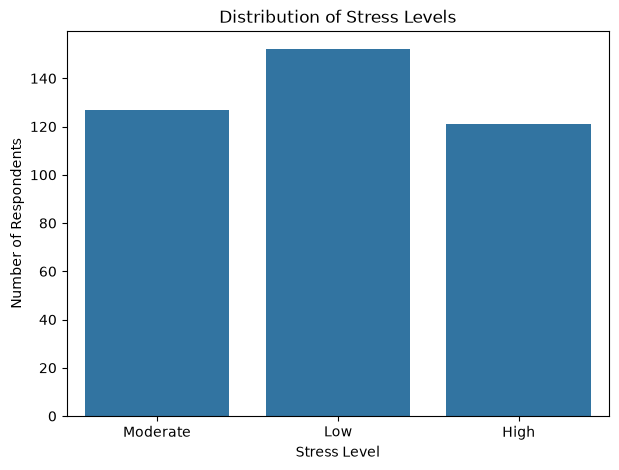

In [121]:
plt.figure(figsize=(7, 5))

sns.countplot(data=data, x=target_column)

plt.title("Distribution of Stress Levels")
plt.xlabel("Stress Level")
plt.ylabel("Number of Respondents")

plt.show()

### 2.2 Numerical Feature Analysis

In [122]:
data.describe()

,6. How would you rate your sleep quality?,11. How would you rate your current academic/work pressure?,19. How would you rate your current financial stress?
count,400.000000,400.00000,400.000000
mean,2.997500,2.87500,3.020000
std,1.177267,1.29753,1.156696
min,1.000000,1.00000,1.000000
25%,2.000000,2.00000,2.000000
50%,3.000000,3.00000,3.000000
75%,4.000000,4.00000,4.000000
max,5.000000,5.00000,5.000000


### 2.3 Sleep Quality and Stress Level

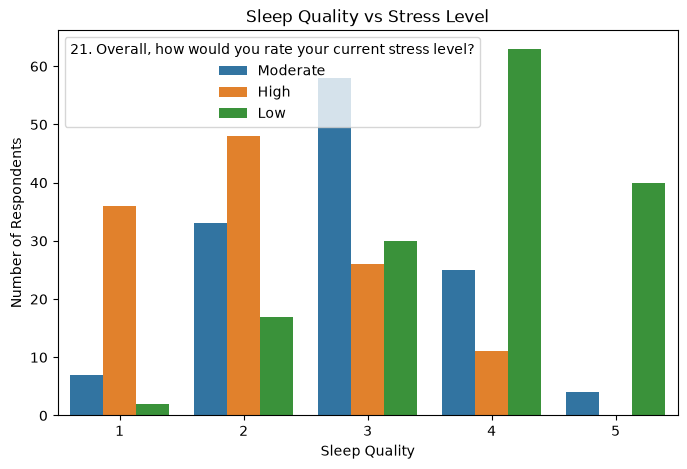

In [123]:
sleep_column = "6. How would you rate your sleep quality?"

plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x=sleep_column,
    hue=target_column
)

plt.title("Sleep Quality vs Stress Level")
plt.xlabel("Sleep Quality")
plt.ylabel("Number of Respondents")

plt.show()

### 2.4 Academic/Work Pressure and Stress Level

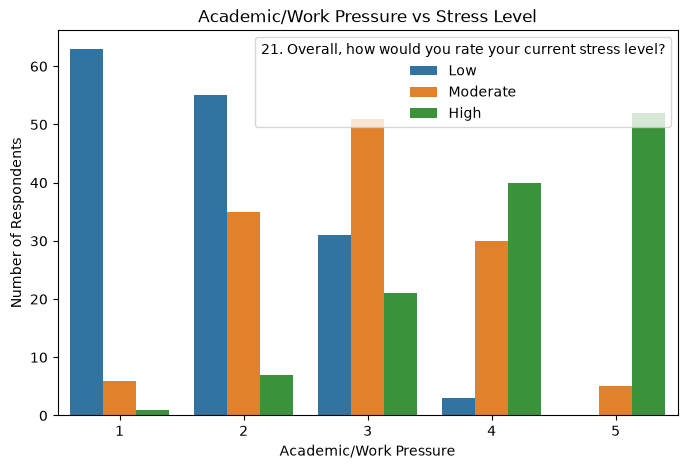

In [124]:
pressure_column = "11. How would you rate your current academic/work pressure?"

plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x=pressure_column,
    hue=target_column
)

plt.title("Academic/Work Pressure vs Stress Level")
plt.xlabel("Academic/Work Pressure")
plt.ylabel("Number of Respondents")

plt.show()

### 2.5 Financial Stress and Stress Level

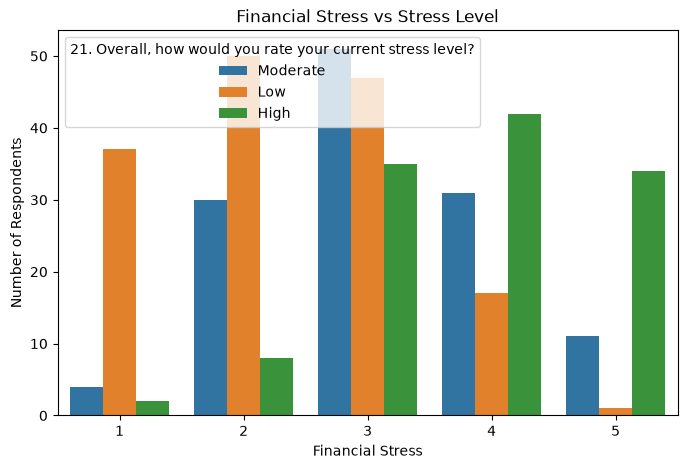

In [125]:
financial_column = "19. How would you rate your current financial stress?"

plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x=financial_column,
    hue=target_column
)

plt.title("Financial Stress vs Stress Level")
plt.xlabel("Financial Stress")
plt.ylabel("Number of Respondents")

plt.show()

## 3. Data Preprocessing

Before training the machine learning models, the dataset must be prepared appropriately.

The preprocessing stage will include:

- Removing unnecessary columns
- Handling missing values
- Checking duplicate records
- Encoding categorical variables
- Scaling numerical variables where required
- Separating input features from the target variable

### 3.1 Removing Unnecessary Columns

The Timestamp column is not a meaningful predictor of stress level. Therefore, it is removed before further analysis.

The consent question is also not used as a predictive feature because all participants included in the dataset have agreed to participate.

In [126]:
# Create a copy of the dataset before preprocessing

processed_data = data.copy()

# Remove unnecessary columns
processed_data = processed_data.drop(
    columns=[
        "Timestamp",
        "1. Do you agree to participate in this anonymous academic survey?"
    ]
)

print("Columns after removing unnecessary variables:")
print(processed_data.columns.tolist())

Columns after removing unnecessary variables:
['2. What is your age group?', '3. What is your gender?', '4. What is your current main status?', '5. On average, how many hours do you sleep per night?', '6. How would you rate your sleep quality?', '7. Approximately how many hours per day do you spend on screens outside essential study/work?', '8. How often do you engage in physical activity or exercise?', '9. How often do you spend time socializing with friends, family, or others?', '10. Approximately how many hours per day do you spend studying or working?', '11. How would you rate your current academic/work pressure?', '12. How often do you feel that you have too much studying/work to manage?', '13. How often do you have difficulty concentrating on your studies/work?', '14. How often have you felt nervous or worried recently?', '15. How often have you felt overwhelmed by your responsibilities?', '16. How often have you felt mentally or emotionally tired?', '17. How often have you had d

### 3.2 Checking Missing Values

In [127]:
missing_values = data.isnull().sum()

print(missing_values)

Timestamp                                                                                        0
1. Do you agree to participate in this anonymous academic survey?                                0
2. What is your age group?                                                                       0
3. What is your gender?                                                                          0
4. What is your current main status?                                                             0
5. On average, how many hours do you sleep per night?                                            0
6. How would you rate your sleep quality?                                                        0
7. Approximately how many hours per day do you spend on screens outside essential study/work?    0
8. How often do you engage in physical activity or exercise?                                     0
9. How often do you spend time socializing with friends, family, or others?                      0
10. Approx

### 3.3 Checking Duplicate Records

Duplicate records are checked to determine whether identical responses occur more than once in the dataset.

In [128]:
duplicate_count = processed_data.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### 3.4 Encoding Categorical and Ordinal Variables

Several survey questions contain categorical or ordered responses such as "Never", "Rarely", "Sometimes", "Often", and "Very often".

These responses need to be converted into numerical representations before they can be used by the machine learning algorithms.

For ordered responses, the numerical values preserve the order of the categories.

In [129]:
# Frequency scale encoding
frequency_mapping = {
    "Never": 0,
    "Rarely": 1,
    "Sometimes": 2,
    "Often": 3,
    "Very often": 4
}

frequency_columns = [
    "9. How often do you spend time socializing with friends, family, or others?",
    "12. How often do you feel that you have too much studying/work to manage?",
    "13. How often do you have difficulty concentrating on your studies/work?",
    "14. How often have you felt nervous or worried recently?",
    "15. How often have you felt overwhelmed by your responsibilities?",
    "16. How often have you felt mentally or emotionally tired?",
    "17. How often have you had difficulty relaxing?",
    "18. How often have you felt unable to cope with the things you needed to do?",
    "20. How often do personal responsibilities interfere with your studies/work?"
]

for column in frequency_columns:
    processed_data[column] = processed_data[column].map(frequency_mapping)

print("Frequency variables encoded successfully.")

Frequency variables encoded successfully.


### 3.5 Encoding Sleep Quality, Pressure and Financial Stress

Sleep quality, academic/work pressure, and financial stress were collected using a 1–5 scale.

These variables are already numerical and therefore do not require categorical encoding.

### 3.6 Encoding Other Ordered Survey Variables

Other ordered categorical variables such as sleep duration, screen time, physical activity, and study/work hours are converted into numerical scores while preserving their natural order.

In [130]:
sleep_hours_mapping = {
    "Less than 4 hours": 0,
    "4–5 hours": 1,
    "6–7 hours": 2,
    "8–9 hours": 3,
    "More than 9 hours": 4
}

screen_time_mapping = {
    "Less than 2 hours": 0,
    "2–4 hours": 1,
    "4–6 hours": 2,
    "6–8 hours": 3,
    "More than 8 hours": 4
}

exercise_mapping = {
    "Never": 0,
    "1 day per week": 1,
    "2–3 days per week": 2,
    "4–5 days per week": 3,
    "6–7 days per week": 4
}

study_work_mapping = {
    "Less than 2 hours": 0,
    "2–4 hours": 1,
    "4–6 hours": 2,
    "6–8 hours": 3,
    "More than 8 hours": 4
}

processed_data[
    "5. On average, how many hours do you sleep per night?"
] = processed_data[
    "5. On average, how many hours do you sleep per night?"
].map(sleep_hours_mapping)

processed_data[
    "7. Approximately how many hours per day do you spend on screens outside essential study/work?"
] = processed_data[
    "7. Approximately how many hours per day do you spend on screens outside essential study/work?"
].map(screen_time_mapping)

processed_data[
    "8. How often do you engage in physical activity or exercise?"
] = processed_data[
    "8. How often do you engage in physical activity or exercise?"
].map(exercise_mapping)

processed_data[
    "10. Approximately how many hours per day do you spend studying or working?"
] = processed_data[
    "10. Approximately how many hours per day do you spend studying or working?"
].map(study_work_mapping)

print("Ordered categorical variables encoded successfully.")

Ordered categorical variables encoded successfully.


### 3.7 Checking the Encoded Dataset

After encoding, the data types and values are checked to ensure that the transformation was performed correctly.

In [131]:
processed_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 20 columns):
 #   Column                                                                                         Non-Null Count  Dtype
---  ------                                                                                         --------------  -----
 0   2. What is your age group?                                                                     400 non-null    str  
 1   3. What is your gender?                                                                        400 non-null    str  
 2   4. What is your current main status?                                                           400 non-null    str  
 3   5. On average, how many hours do you sleep per night?                                          400 non-null    int64
 4   6. How would you rate your sleep quality?                                                      400 non-null    int64
 5   7. Approximately how many hours per day do you 

In [132]:
processed_data.head()

,2. What is your age group?,3. What is your gender?,4. What is your current main status?,"5. On average, how many hours do you sleep per night?",6. How would you rate your sleep quality?,7. Approximately how many hours per day do you spend on screens outside essential study/work?,8. How often do you engage in physical activity or exercise?,"9. How often do you spend time socializing with friends, family, or others?",10. Approximately how many hours per day do you spend studying or working?,11. How would you rate your current academic/work pressure?,12. How often do you feel that you have too much studying/work to manage?,13. How often do you have difficulty concentrating on your studies/work?,14. How often have you felt nervous or worried recently?,15. How often have you felt overwhelmed by your responsibilities?,16. How often have you felt mentally or emotionally tired?,17. How often have you had difficulty relaxing?,18. How often have you felt unable to cope with the things you needed to do?,19. How would you rate your current financial stress?,20. How often do personal responsibilities interfere with your studies/work?,"21. Overall, how would you rate your current stress level?"
0,18–20,Female,Student,0,3,2,2,2,1,3,1,4,3,3,4,1,2,1,2,Moderate
1,24–26,Male,Student,2,3,1,2,0,3,3,0,0,0,0,1,1,1,2,2,Low
2,18–20,Female,Employed,2,2,2,1,4,3,2,2,3,1,2,3,3,4,5,3,Moderate
3,27–30,Male,Student,2,2,2,1,1,3,4,1,2,4,3,4,4,4,4,4,High
4,21–23,Male,Student,3,4,2,4,2,0,2,0,0,0,0,0,0,0,2,0,Low


## 4. Feature Engineering

Feature engineering is the process of creating meaningful new variables from existing variables.

For this project, two composite features will be created:

1. Lifestyle Score
2. Pressure Score

These features combine related survey responses into broader indicators that may help the machine learning models identify patterns associated with stress levels.

### 4.1 Lifestyle Score

The Lifestyle Score combines several lifestyle-related factors:

- Sleep quality
- Physical activity
- Social interaction
- Screen time

Higher sleep quality, physical activity, and social interaction contribute positively to the score, while higher screen time contributes negatively.

The resulting score provides a combined representation of lifestyle-related factors.

In [133]:
# Create Lifestyle Score

sleep_quality = (
    processed_data[
        "6. How would you rate your sleep quality?"
    ] / 5
)

physical_activity = (
    processed_data[
        "8. How often do you engage in physical activity or exercise?"
    ] / 4
)

social_interaction = (
    processed_data[
        "9. How often do you spend time socializing with friends, family, or others?"
    ] / 4
)

screen_time = (
    processed_data[
        "7. Approximately how many hours per day do you spend on screens outside essential study/work?"
    ] / 4
)

processed_data["Lifestyle_Score"] = (
    sleep_quality
    + physical_activity
    + social_interaction
    - screen_time
)

print(processed_data["Lifestyle_Score"].describe())

count    400.000000
mean       1.140125
std        0.552650
min       -0.350000
25%        0.700000
50%        1.100000
75%        1.550000
max        2.750000
Name: Lifestyle_Score, dtype: float64


### 4.2 Pressure Score

The Pressure Score combines factors related to academic/work and personal pressure:

- Academic/work pressure
- Work/study overload
- Financial stress
- Personal responsibilities

The score provides a combined representation of the different pressure-related factors reported by each respondent.

In [134]:
# Create Pressure Score

academic_pressure = (
    processed_data[
        "11. How would you rate your current academic/work pressure?"
    ] / 5
)

workload_pressure = (
    processed_data[
        "12. How often do you feel that you have too much studying/work to manage?"
    ] / 4
)

financial_pressure = (
    processed_data[
        "19. How would you rate your current financial stress?"
    ] / 5
)

personal_pressure = (
    processed_data[
        "20. How often do personal responsibilities interfere with your studies/work?"
    ] / 4
)

processed_data["Pressure_Score"] = (
    academic_pressure
    + workload_pressure
    + financial_pressure
    + personal_pressure
)

print(processed_data["Pressure_Score"].describe())

count    400.000000
mean       2.082125
std        0.941816
min        0.400000
25%        1.300000
50%        2.100000
75%        2.762500
max        4.000000
Name: Pressure_Score, dtype: float64


### 4.3 Checking the New Features

The newly created features are examined to verify that they contain valid numerical values and to understand their distributions.

In [135]:
print(
    processed_data[
        ["Lifestyle_Score", "Pressure_Score"]
    ].head()
)

   Lifestyle_Score  Pressure_Score
0             1.10            1.55
1             0.85            1.50
2             1.15            2.65
3             0.40            2.85
4             1.80            0.80


In [136]:
print(
    processed_data[
        ["Lifestyle_Score", "Pressure_Score"]
    ].describe()
)

       Lifestyle_Score  Pressure_Score
count       400.000000      400.000000
mean          1.140125        2.082125
std           0.552650        0.941816
min          -0.350000        0.400000
25%           0.700000        1.300000
50%           1.100000        2.100000
75%           1.550000        2.762500
max           2.750000        4.000000


### 4.4 Visualising the Engineered Features

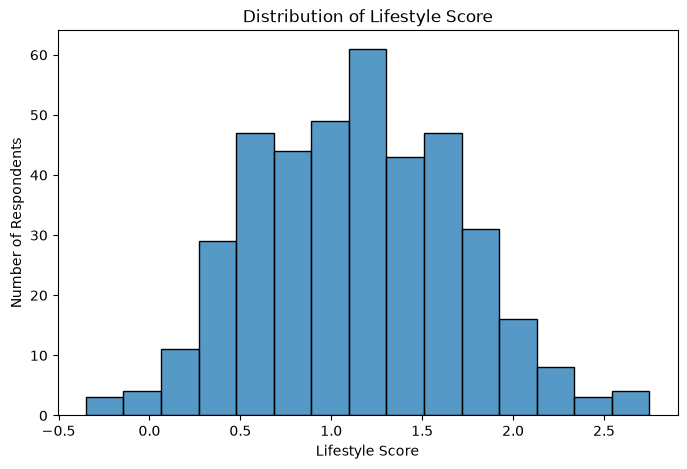

In [137]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=processed_data,
    x="Lifestyle_Score",
    bins=15
)

plt.title("Distribution of Lifestyle Score")
plt.xlabel("Lifestyle Score")
plt.ylabel("Number of Respondents")

plt.show()

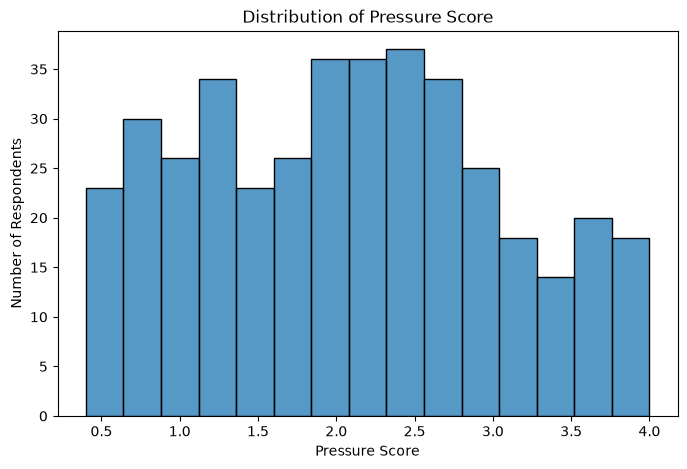

In [138]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=processed_data,
    x="Pressure_Score",
    bins=15
)

plt.title("Distribution of Pressure Score")
plt.xlabel("Pressure Score")
plt.ylabel("Number of Respondents")

plt.show()

### 4.5 Feature Engineering Summary

Two new features were successfully created from the existing survey variables:

- `Lifestyle_Score`
- `Pressure_Score`

These engineered features will be included as candidate input variables during the machine learning stage.

# Categorical Encoding

Some variables such as age group, gender, and current status are categorical variables.

Machine learning algorithms require numerical input, therefore these categorical variables will be converted into numerical representations using one-hot encoding.

One-hot encoding creates separate binary columns for each category without imposing an artificial numerical order.

### Separating Features and Target

The target variable is the respondent's overall stress level.

All remaining variables will be considered candidate input features.

In [139]:
target_column = "21. Overall, how would you rate your current stress level?"

X = processed_data.drop(columns=[target_column])
y = processed_data[target_column]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Feature shape: (400, 21)
Target shape: (400,)

Target classes:
21. Overall, how would you rate your current stress level?
Low         152
Moderate    127
High        121
Name: count, dtype: int64


### Identifying Categorical and Numerical Features

The features are divided into categorical and numerical variables.

Categorical variables will be one-hot encoded, while numerical variables will be retained as numerical values and scaled later where appropriate.

In [140]:
categorical_features = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['2. What is your age group?', '3. What is your gender?', '4. What is your current main status?']

Numerical features:
['5. On average, how many hours do you sleep per night?', '6. How would you rate your sleep quality?', '7. Approximately how many hours per day do you spend on screens outside essential study/work?', '8. How often do you engage in physical activity or exercise?', '9. How often do you spend time socializing with friends, family, or others?', '10. Approximately how many hours per day do you spend studying or working?', '11. How would you rate your current academic/work pressure?', '12. How often do you feel that you have too much studying/work to manage?', '13. How often do you have difficulty concentrating on your studies/work?', '14. How often have you felt nervous or worried recently?', '15. How often have you felt overwhelmed by your responsibilities?', '16. How often have you felt mentally or emotionally tired?', '17. How often have you had dif

### Creating the Preprocessing Pipeline

A preprocessing pipeline is created to apply the required transformations consistently.

Categorical variables will be converted using One-Hot Encoding.

Numerical variables will be standardized using StandardScaler.

Using a pipeline helps ensure that the same preprocessing steps are applied consistently during model training and prediction.

In [141]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


# 5. Train-Test Split

The dataset will be divided into training and testing subsets.

The training set will be used to train the machine learning models, while the testing set will be kept separate and used to evaluate how well the trained models perform on unseen data.

An 80:20 split will be used:

- 80% Training data
- 20% Testing data

Stratification will be used to maintain a similar distribution of the stress-level classes in both subsets.

In [142]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 320
Testing samples: 80


### 5.1 Checking Class Distribution After the Split

The target-class distribution is checked after splitting to confirm that stratification has maintained a reasonable distribution of Low, Moderate, and High stress classes.

In [143]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
21. Overall, how would you rate your current stress level?
Low         121
Moderate    102
High         97
Name: count, dtype: int64

Testing target distribution:
21. Overall, how would you rate your current stress level?
Low         31
Moderate    25
High        24
Name: count, dtype: int64


# 6. Model Selection and Training

Three classification algorithms will be implemented and compared for predicting the respondent's stress level:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

These models represent different approaches to classification and allow their predictive performance to be compared using the same training and testing data.

### 6.1 Logistic Regression

Logistic Regression is selected as a baseline classification model.

It provides a relatively simple model that can be used as a reference point when comparing the performance of more complex models.

In [144]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


### 6.2 Decision Tree Classifier

A Decision Tree Classifier is used to learn decision rules from the input features.

The model can represent non-linear relationships between the survey variables and stress-level classes.

In [145]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42,
            max_depth=5
        ))
    ]
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


### 6.3 Random Forest Classifier

Random Forest is an ensemble learning method that combines multiple decision trees.

It is included to determine whether an ensemble model can provide better predictive performance than the individual baseline models.

In [146]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            max_depth=5
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


# 7. Model Evaluation

The trained models will now be evaluated using the unseen testing dataset.

The following evaluation metrics will be considered:

- Accuracy
- Precision
- Recall
- F1-score

These metrics provide a more complete assessment of classification performance than accuracy alone.

In [147]:
# Generate predictions

logistic_predictions = logistic_model.predict(X_test)
decision_tree_predictions = decision_tree_model.predict(X_test)
random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions generated successfully.")

Predictions generated successfully.


### 7.1 Evaluation Function

A common evaluation function will be used so that all three models are evaluated using the same metrics.

In [148]:
def evaluate_model(model_name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

In [149]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_predictions
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        decision_tree_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        random_forest_predictions
    )
)

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7750,0.769067,0.7750,0.764822
1,Decision Tree,0.7125,0.706220,0.7125,0.708260
2,Random Forest,0.7250,0.709838,0.7250,0.709071


# 8. Confusion Matrix

A confusion matrix will be used to examine the classification errors made by each model.

It shows how many observations from each actual stress category were correctly or incorrectly classified as Low, Moderate, or High.

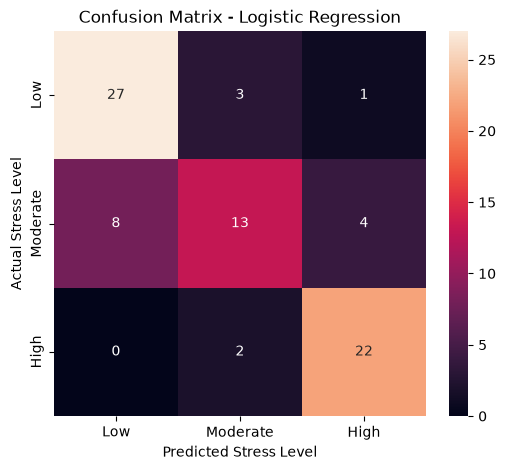

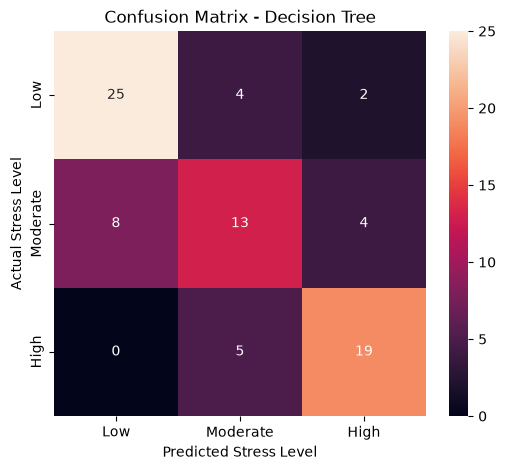

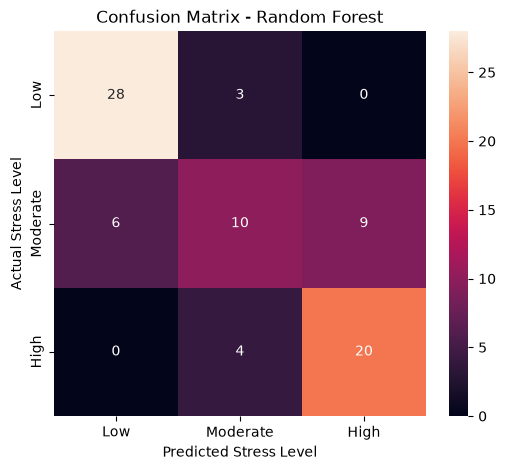

In [150]:
models_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions
}

for model_name, predictions in models_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["Low", "Moderate", "High"]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Low", "Moderate", "High"],
        yticklabels=["Low", "Moderate", "High"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Stress Level")
    plt.ylabel("Actual Stress Level")

    plt.show()

# 9. Cross-Validation

A single train-test split may not provide a complete picture of model performance.

Therefore, k-fold cross-validation will be used to evaluate the three classification models across multiple subsets of the training data.

Five-fold cross-validation will be used in this project.

The mean cross-validation score and standard deviation will be compared for each model.

In [151]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold stratified cross-validation created.")

5-fold stratified cross-validation created.


### 9.1 Cross-Validation of Logistic Regression

In [152]:
logistic_cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_weighted"
)

print("Logistic Regression CV Scores:")
print(logistic_cv_scores)

print("\nMean F1-Score:", logistic_cv_scores.mean())
print("Standard Deviation:", logistic_cv_scores.std())

Logistic Regression CV Scores:
[0.68501038 0.75157524 0.74676927 0.73581144 0.65216228]

Mean F1-Score: 0.7142657214335453
Standard Deviation: 0.039052303741034314


### 9.2 Cross-Validation of Decision Tree

In [153]:
decision_tree_cv_scores = cross_val_score(
    decision_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_weighted"
)

print("Decision Tree CV Scores:")
print(decision_tree_cv_scores)

print("\nMean F1-Score:", decision_tree_cv_scores.mean())
print("Standard Deviation:", decision_tree_cv_scores.std())

Decision Tree CV Scores:
[0.71074035 0.73426974 0.70356912 0.66459295 0.69225146]

Mean F1-Score: 0.7010847251669731
Standard Deviation: 0.022848743025028994


### 9.3 Cross-Validation of Random Forest

In [154]:
random_forest_cv_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_weighted"
)

print("Random Forest CV Scores:")
print(random_forest_cv_scores)

print("\nMean F1-Score:", random_forest_cv_scores.mean())
print("Standard Deviation:", random_forest_cv_scores.std())

Random Forest CV Scores:
[0.79774091 0.74765625 0.69569349 0.77099577 0.66455853]

Mean F1-Score: 0.7353289909280775
Standard Deviation: 0.048782698648960364


### 9.4 Cross-Validation Comparison

The cross-validation results of the three models will be compared using the mean weighted F1-score.

A higher mean F1-score indicates better overall classification performance across the cross-validation folds, while a lower standard deviation indicates more consistent performance between folds.

In [155]:
cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Mean CV F1": [
        logistic_cv_scores.mean(),
        decision_tree_cv_scores.mean(),
        random_forest_cv_scores.mean()
    ],
    "CV Standard Deviation": [
        logistic_cv_scores.std(),
        decision_tree_cv_scores.std(),
        random_forest_cv_scores.std()
    ]
})

cv_results.sort_values(
    by="Mean CV F1",
    ascending=False
)

,Model,Mean CV F1,CV Standard Deviation
2,Random Forest,0.735329,0.048783
0,Logistic Regression,0.714266,0.039052
1,Decision Tree,0.701085,0.022849


# 10. Hyperparameter Tuning

Hyperparameter tuning will be performed to identify suitable parameter values for the machine learning models.

Grid Search will be used to evaluate different combinations of hyperparameters using cross-validation.

The Random Forest model will be tuned because it provides an ensemble approach and can be optimized using parameters such as the number of trees and maximum tree depth.

In [156]:
from sklearn.model_selection import GridSearchCV

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            random_state=42
        ))
    ]
)

param_grid = {
    "classifier__n_estimators": [50, 100, 200],
    "classifier__max_depth": [3, 5, 10, None],
    "classifier__min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_weighted",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Grid Search completed.")

Grid Search completed.


In [157]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 50}

Best Cross-Validation F1-Score:
0.7489366620559629


### 10.1 Best Tuned Model

The best Random Forest configuration identified by Grid Search will be used as the tuned model for the final evaluation on the unseen test dataset.

In [158]:
best_model = grid_search.best_estimator_

tuned_predictions = best_model.predict(X_test)

tuned_accuracy = accuracy_score(
    y_test,
    tuned_predictions
)

tuned_precision = precision_score(
    y_test,
    tuned_predictions,
    average="weighted",
    zero_division=0
)

tuned_recall = recall_score(
    y_test,
    tuned_predictions,
    average="weighted",
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    tuned_predictions,
    average="weighted",
    zero_division=0
)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("Accuracy :", tuned_accuracy)
print("Precision:", tuned_precision)
print("Recall   :", tuned_recall)
print("F1-Score :", tuned_f1)

Tuned Random Forest Performance
--------------------------------
Accuracy : 0.7625
Precision: 0.7541351010101011
Recall   : 0.7625
F1-Score : 0.7549121732026144


# 11. Final Model Comparison

The performance of the initial classification models and the tuned Random Forest model will be compared using the evaluation metrics obtained from the unseen test dataset.

The main metrics considered are:

- Accuracy
- Precision
- Recall
- F1-Score

The F1-Score will be given particular attention because it provides a balance between precision and recall.

In [159]:
final_results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_predictions
    ),
    evaluate_model(
        "Decision Tree",
        y_test,
        decision_tree_predictions
    ),
    evaluate_model(
        "Random Forest",
        y_test,
        random_forest_predictions
    ),
    evaluate_model(
        "Tuned Random Forest",
        y_test,
        tuned_predictions
    )
])

final_results = final_results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

final_results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7750,0.769067,0.7750,0.764822
1,Tuned Random Forest,0.7625,0.754135,0.7625,0.754912
2,Random Forest,0.7250,0.709838,0.7250,0.709071
3,Decision Tree,0.7125,0.706220,0.7125,0.708260


# 12. Best Model Selection

The final model will be selected based on its performance on the unseen test dataset.

The F1-Score is used as the primary selection metric, while accuracy, precision, and recall are also considered.

The model with the strongest overall performance will be selected as the final model for deployment.

In [160]:
best_model_name = final_results.loc[0, "Model"]

print("Best Model:", best_model_name)
print("\nPerformance:")
print(final_results.iloc[0])

Best Model: Logistic Regression

Performance:
Model        Logistic Regression
Accuracy                   0.775
Precision               0.769067
Recall                     0.775
F1-Score                0.764822
Name: 0, dtype: object


## 13. Final Model Confusion Matrix

The confusion matrix of the selected final model is examined to understand its correct and incorrect predictions across the Low, Moderate, and High stress categories.

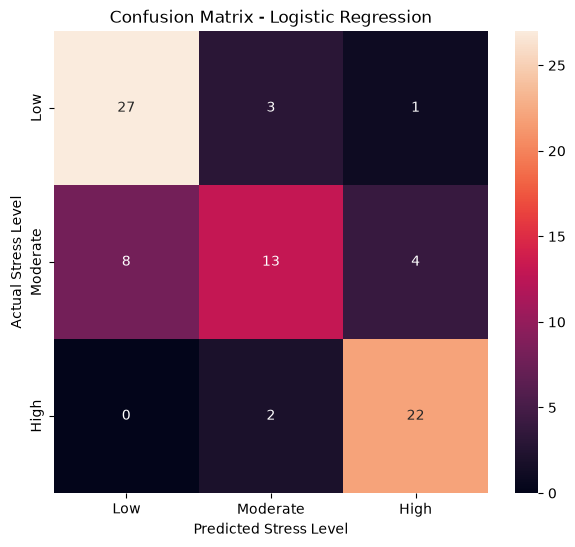

In [161]:
best_predictions = logistic_predictions

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Low", "Moderate", "High"]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Low", "Moderate", "High"],
    yticklabels=["Low", "Moderate", "High"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Stress Level")
plt.ylabel("Actual Stress Level")

plt.show()

## 14. Detailed Classification Report

A detailed classification report is generated to examine precision, recall, and F1-score for each individual stress-level class.

In [162]:
print(
    classification_report(
        y_test,
        best_predictions,
        labels=["Low", "Moderate", "High"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       0.77      0.87      0.82        31
    Moderate       0.72      0.52      0.60        25
        High       0.81      0.92      0.86        24

    accuracy                           0.78        80
   macro avg       0.77      0.77      0.76        80
weighted avg       0.77      0.78      0.76        80



# 15. Final Model Training

Logistic Regression was selected as the best-performing model based on the model comparison results.

The selected model will now be fitted using the complete available training dataset and prepared for saving and future predictions.

In [163]:
# Use Logistic Regression as the final model

final_model = logistic_model

print("Final model selected: Logistic Regression")

Final model selected: Logistic Regression


## 16 . Saving the Final Model

The final trained model will be saved so that it can be loaded later without repeating the complete training process.

The preprocessing steps and Logistic Regression classifier are contained within the pipeline.

In [164]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

model_path = "../models/mental_health_stress_model.pkl"

joblib.dump(final_model, model_path)

print("Final model saved successfully.")
print("Location:", model_path)

Final model saved successfully.
Location: ../models/mental_health_stress_model.pkl


## 17. Loading the Saved Model

The saved model is loaded again to verify that it can be used for prediction after the training process.

In [165]:
loaded_model = joblib.load(model_path)

print("Saved model loaded successfully.")
print(type(loaded_model))

Saved model loaded successfully.
<class 'sklearn.pipeline.Pipeline'>


# 18. New Respondent Prediction

A new respondent's survey information can be passed to the saved model.

The model will process the input using the same preprocessing steps and predict one of the three stress-level categories:

- Low
- Moderate
- High

In [166]:
def predict_stress(new_data):
    prediction = loaded_model.predict(new_data)
    return prediction[0]

#  Conclusion

This project developed a machine learning classification system for predicting self-reported stress levels.

The workflow included data collection, exploratory data analysis, preprocessing, feature engineering, model training, model comparison, cross-validation, and hyperparameter tuning.

Three initial classification models were evaluated together with a tuned Random Forest model.

Based on the evaluation results, Logistic Regression achieved the best overall performance and was therefore selected as the final model.

The final model was saved as a reusable pipeline so that it can be used to make predictions for new survey responses.